# Exercise 4.2 — ReLU networks on the checkerboard

[Open the XOR dataset in TensorFlow Playground](https://playground.tensorflow.org/#activation=relu&batchSize=10&dataset=xor&learningRate=0.03&networkShape=4,2&seed=0.01348&showTestData=true&percTrainData=50&x=true&y=true&xTimesY=false&problem=classification).

1. Try various settings for the number of layers and neurons using ReLU as activation function. What is the smallest network that gives a good fit result?
2. What do you observe when training networks with the same
3. Try additional input features: Which one is most helpful?

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Reproduce the Playground's XOR data rule with a fixed NumPy seed.
rng = np.random.default_rng(1234)
# Generate 500 points uniformly in [-5, 5]². The Playground's points are in [-4.7, 4.7]², but the extra margin makes the decision boundary more visible. 
points = rng.uniform(-5, 5, size=(500, 2))
# Move points 0.3 units away from each axis, as in the Playground.
points += 0.3 * np.where(points >= 0, 1, -1)
# The coordinates are sampled independently. Their signs together determine the class.
labels = np.where(points[:, 0] * points[:, 1] >= 0, 1, -1)
# Use the same 50/50 split for every architecture and feature set.
train_x, test_x = np.split(points, 2)
train_y, test_y = np.split(labels, 2)

# Each feature set keeps the two original coordinates.
features = {
    "raw": lambda x: x,
    "squares": lambda x: np.column_stack((x, x[:, 0] ** 2, x[:, 1] ** 2)),
    "product": lambda x: np.column_stack((x, x[:, 0] * x[:, 1])),
}

# The network's forward pass returns the activations of each layer and the final score.
def forward(x, weights, biases):
    # Save each layer's output so we can reuse it during backpropagation.
    activations = [x]
    # Compute the ReLU of each hidden layer's linear combination of the previous layer's activations.
    for weight, bias in zip(weights[:-1], biases[:-1]):
        activations.append(np.maximum(activations[-1] @ weight + bias, 0))
    # Tanh gives a score between -1 and 1. Its sign determines the class.
    score = np.tanh(activations[-1] @ weights[-1] + biases[-1])
    return activations, score

# Train a network with the given hidden layer shape and feature set. Return a function that predicts the class of new points.
def train(shape, feature_name, seed, epochs=300):
    rng = np.random.default_rng(seed)    
    transform = features[feature_name]
    x = transform(train_x)
    
    # Include the input width, any hidden layers, and one output unit.
    sizes = (x.shape[1], *shape, 1)
    weights = [rng.uniform(-0.5, 0.5, (a, b)) for a, b in zip(sizes, sizes[1:])]
    biases = [np.full(b, 0.1) for b in sizes[1:]]
    
    for _ in range(epochs):
        # Shuffle the training examples and update the network every 10 points.
        for batch in rng.permutation(len(x)).reshape(-1, 10):
            activations, score = forward(x[batch], weights, biases)
            # Differentiate the half-squared error and multiply by the tanh slope.
            error = score - train_y[batch, None]
            tanh_slope = 1 - score**2
            delta = error * tanh_slope / len(batch)
            for layer in reversed(range(len(weights))):
                # Pass the gradient back using the current weights. ReLU blocks it at inactive units.
                previous_delta = (delta @ weights[layer].T) * (activations[layer] > 0)
                # Average batch gradients are already scaled by 1 / batch size in delta.
                dW = activations[layer].T @ delta
                db = delta.sum(axis=0)
                weights[layer] -= 0.03 * dW
                biases[layer] -= 0.03 * db
                delta = previous_delta

    def predict(points):
        return forward(transform(points), weights, biases)[1][:, 0]

    return predict

In [2]:
# 1. Compare widths and depths. An empty tuple means no hidden layer.
shapes = [(), (1,), (2,), (1, 1), (3,), (1, 2), (2, 1), (4,), (2, 2), (4, 2)]
# 2. Repeat each shape with different initial weights and minibatch orders.
seeds = range(5)
trials = {}

def compare(shape, feature_name):
    models = [train(shape, feature_name, seed) for seed in seeds]
    # Measure held-out accuracy by comparing the sign of each score with its label.
    accuracy = np.zeros(len(models))
    for i, model in enumerate(models):
        y_pred = np.where(model(test_x) >= 0, 1, -1)
        accuracy[i] = np.mean(y_pred == test_y)
    trials[shape, feature_name] = models, accuracy
    scores = " ".join(f"{value:6.1%}" for value in accuracy)
    print(f"{str(shape):>8}  {feature_name:<8} {scores}  {np.mean(accuracy >= .95):6.0%}")

print("   Shape  Features     Seed 0  Seed 1  Seed 2  Seed 3  Seed 4    Pass")
for shape in shapes:
    compare(shape, "raw")

# Treat at least 95% test accuracy as a good fit for this experiment.
smallest = next(
    (shape for shape in shapes if np.any(trials[shape, "raw"][1] >= .95)),
    None,
)
print(f"Smallest tested shape with a successful run: {smallest}")

# The second question in the prompt is unfinished. I interpreted it as
# repeating training with the same architecture.

   Shape  Features     Seed 0  Seed 1  Seed 2  Seed 3  Seed 4    Pass
      ()  raw       48.4%  44.0%  68.0%  64.0%  58.4%      0%
    (1,)  raw       69.2%  66.8%  71.2%  70.4%  67.2%      0%
    (2,)  raw       77.2%  78.0%  73.6%  73.6%  78.0%      0%
  (1, 1)  raw       66.0%  50.4%  66.0%  70.4%  68.8%      0%
    (3,)  raw      100.0% 100.0% 100.0% 100.0% 100.0%    100%
  (1, 2)  raw       69.2%  85.2%  88.4%  70.4%  74.4%      0%
  (2, 1)  raw       70.4%  50.4%  84.8%  88.8%  76.0%      0%
    (4,)  raw      100.0% 100.0% 100.0% 100.0% 100.0%    100%
  (2, 2)  raw       89.6%  88.4%  73.6%  77.6%  87.6%      0%
  (4, 2)  raw      100.0% 100.0% 100.0% 100.0%  88.0%     80%
Smallest tested shape with a successful run: (3,)


      ()  squares   77.2%  77.2%  77.2%  77.2%  71.6%      0%
      ()  product  100.0% 100.0% 100.0% 100.0% 100.0%    100%


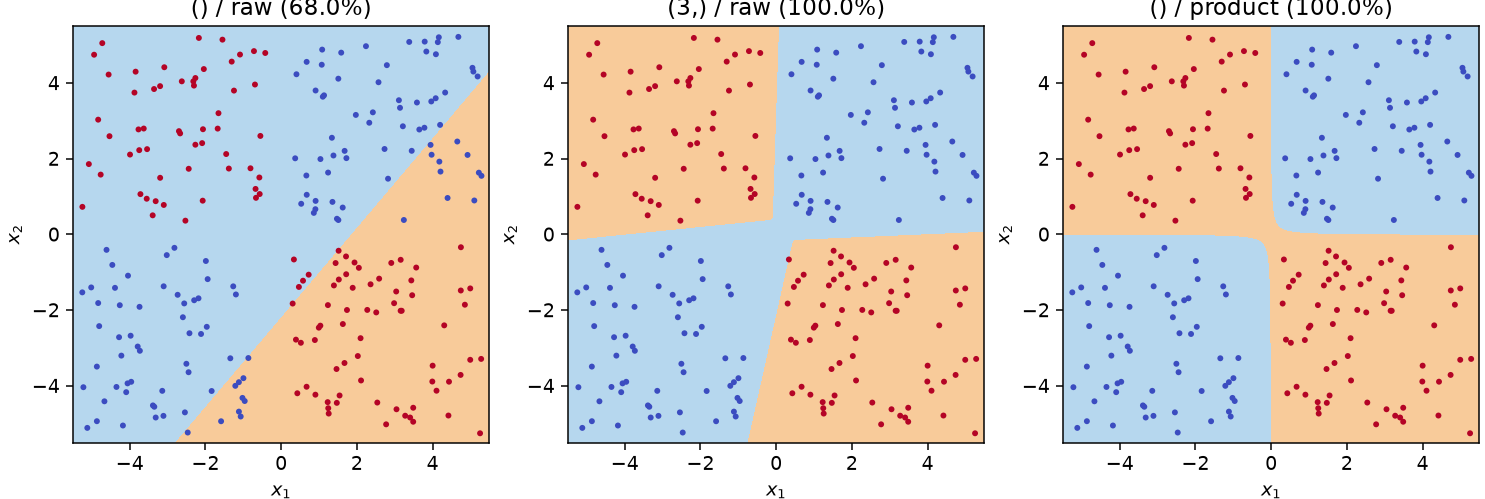

In [3]:
# 3. Compare extra features with the hidden layers removed.
compare((), "squares")
compare((), "product")

# Evaluate scores on a grid to draw the decision regions.
axis_values = np.linspace(-5.5, 5.5, 161)
xx, yy = np.meshgrid(axis_values, axis_values)
grid = np.column_stack((xx.ravel(), yy.ravel()))
fig, axes = plt.subplots(1, 3, figsize=(11, 3.7), layout="constrained")
for ax, shape, feature_name in zip(axes, [(), smallest, ()], ["raw", "raw", "product"]):
    models, scores = trials[shape, feature_name]
    # Show the best run for each setting and overlay the held-out points.
    best = np.argmax(scores)
    zz = models[best](grid).reshape(xx.shape)
    ax.contourf(xx, yy, zz, levels=[-1, 0, 1], colors=["#f8cb9a", "#b6d7ee"])
    ax.scatter(*test_x.T, c=test_y, cmap="coolwarm_r", vmin=-1, vmax=1,
               s=10, edgecolors="none")
    ax.set(title=f"{shape} / {feature_name} ({scores[best]:.1%})",
           xlabel="$x_1$", ylabel="$x_2$", aspect="equal")
plt.show()

# Conclusion: One hidden layer with three ReLU units was the smallest
# tested raw-input model to pass. It scored 100% in all five runs.
# With the same (4, 2) shape, four runs scored 100% and one scored 88%.
# The product x1*x2 gave 100% without a hidden layer: its sign gives
# the class directly. Squaring the inputs loses their signs.